# Categorical Encoding and Data Leakage with Naive Bayes

This notebook compares three ways of encoding categorical features for Naive Bayes
on a 70k-row health survey (CDC BRFSS 2015), and shows how fitting a target encoder
before the train/test split inflates accuracy from 0.73 to 0.99.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders import CatBoostEncoder
from sklearn.naive_bayes import MultinomialNB, CategoricalNB, GaussianNB

df = pd.read_csv('data/diabetes_70k.csv')
X = df.drop(columns=['class'])
y = df['class']
n_runs = 20

print('Shape:', X.shape)
print(y.value_counts())

Shape: (70692, 21)
class
0    35346
1    35346
Name: count, dtype: int64


*The two classes are balanced, so accuracy is a reasonable metric. All features are treated as categorical.*

## 1. Label-free encoders: One-Hot vs Ordinal
The encoders are fitted on the whole dataset before splitting.
`min_categories` is needed because some rare BMI values can be missing from the training set, which makes `CategoricalNB` fail at prediction.

In [2]:
# Encoding on the whole dataset (before splitting)
X_ohe = OneHotEncoder().fit_transform(X)

ord_enc = OrdinalEncoder()
X_ord = ord_enc.fit_transform(X)
category_counts = [len(cats) for cats in ord_enc.categories_]

acc_ohe_mnb = []
acc_ord_cnb = []

for seed in range(n_runs):
    # OneHot -> MultinomialNB
    X_train, X_test, y_train, y_test = train_test_split(
        X_ohe, y, test_size=0.50, random_state=seed)
    mnb = MultinomialNB().fit(X_train, y_train)
    acc_ohe_mnb.append(accuracy_score(y_test, mnb.predict(X_test)))

    # Ordinal -> CategoricalNB
    X_train, X_test, y_train, y_test = train_test_split(
        X_ord, y, test_size=0.50, random_state=seed)
    cnb = CategoricalNB(min_categories=category_counts).fit(X_train, y_train)
    acc_ord_cnb.append(accuracy_score(y_test, cnb.predict(X_test)))

print(f'OneHotEncoder + MultinomialNB  -> Mean accuracy: {np.mean(acc_ohe_mnb):.4f}')
print(f'OrdinalEncoder + CategoricalNB -> Mean accuracy: {np.mean(acc_ord_cnb):.4f}')

OneHotEncoder + MultinomialNB  -> Mean accuracy: 0.7333
OrdinalEncoder + CategoricalNB -> Mean accuracy: 0.7333


*Both combinations give a mean accuracy of **0.7333**, with the same result in every run. With one-hot input, MultinomialNB uses the same category counts per class as CategoricalNB, so the two models end up making the same predictions.*

## 2. Target encoding: CatBoost + Gaussian NB
CatBoostEncoder replaces each category with a smoothed mean of the target, so its output is continuous and GaussianNB is used. The columns have to be passed with `cols=`, because integer columns are not encoded by default.

In [3]:
# Encoding on the whole dataset (target-based, so it also uses y)
X_cbe = CatBoostEncoder(cols=X.columns.tolist()).fit_transform(X, y)

acc_cb_gnb = []

for seed in range(n_runs):
    X_train, X_test, y_train, y_test = train_test_split(
        X_cbe, y, test_size=0.50, random_state=seed)
    gnb = GaussianNB().fit(X_train, y_train)
    acc_cb_gnb.append(accuracy_score(y_test, gnb.predict(X_test)))

print(f'CatBoostEncoder + GaussianNB -> Mean accuracy: {np.mean(acc_cb_gnb):.4f}')

CatBoostEncoder + GaussianNB -> Mean accuracy: 0.9901


*The **accuracy (0.9901)** is much higher than in Task 1. Since the encoder was fitted using the labels of all rows, including the test rows, this result is probably not reliable.*

## 3. Correct workflow: fitting encoders after the split
Here the data is split first and each encoder is fitted on the training set only, then used to transform both sets.
Since the test set can now contain BMI values not seen in training, `handle_unknown='ignore'` is used for the one-hot encoder and the list of possible values (`categories=`) is given to the ordinal encoder.

In [4]:
# Possible values of each feature (feature values only, no labels)
all_categories = [np.sort(X[col].unique()) for col in X.columns]
category_counts = [len(cats) for cats in all_categories]

acc_ohe_mnb_after = []
acc_ord_cnb_after = []
acc_cb_gnb_after = []

for seed in range(n_runs):
    # 1. Split first
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.50, random_state=seed)

    # 2. OneHot -> MultinomialNB (encoder fitted on training data only)
    ohe = OneHotEncoder(handle_unknown='ignore')
    X_train_ohe = ohe.fit_transform(X_train)
    X_test_ohe = ohe.transform(X_test)
    mnb = MultinomialNB().fit(X_train_ohe, y_train)
    acc_ohe_mnb_after.append(accuracy_score(y_test, mnb.predict(X_test_ohe)))

    # 3. Ordinal -> CategoricalNB
    ord_enc = OrdinalEncoder(categories=all_categories)
    X_train_ord = ord_enc.fit_transform(X_train)
    X_test_ord = ord_enc.transform(X_test)
    cnb = CategoricalNB(min_categories=category_counts).fit(X_train_ord, y_train)
    acc_ord_cnb_after.append(accuracy_score(y_test, cnb.predict(X_test_ord)))

    # 4. CatBoost -> GaussianNB (target statistics computed from training labels only)
    cbe = CatBoostEncoder(cols=X.columns.tolist())
    X_train_cbe = cbe.fit_transform(X_train, y_train)
    X_test_cbe = cbe.transform(X_test)
    gnb = GaussianNB().fit(X_train_cbe, y_train)
    acc_cb_gnb_after.append(accuracy_score(y_test, gnb.predict(X_test_cbe)))

print(f'OneHotEncoder + MultinomialNB  -> Mean accuracy: {np.mean(acc_ohe_mnb_after):.4f}')
print(f'OrdinalEncoder + CategoricalNB -> Mean accuracy: {np.mean(acc_ord_cnb_after):.4f}')
print(f'CatBoostEncoder + GaussianNB   -> Mean accuracy: {np.mean(acc_cb_gnb_after):.4f}')

OneHotEncoder + MultinomialNB  -> Mean accuracy: 0.7333
OrdinalEncoder + CategoricalNB -> Mean accuracy: 0.7333
CatBoostEncoder + GaussianNB   -> Mean accuracy: 0.7282


In [5]:
print('Number of times the class changes along the file:', (y.diff() != 0).sum() - 1)

Number of times the class changes along the file: 1


### Why CatBoost drops from 0.99 to 0.73
*Data leakage happens when information from the test set is used to build the model, so the test accuracy overestimates the real performance.*

***OneHot** and **Ordinal** give the same accuracy before and after splitting (**0.7333**), because these encoders do not use the labels.
**CatBoost** instead drops from **0.9901** to **0.7282**. Being a target encoder, when fitted on the whole dataset it used the test labels to build the features. The effect is stronger here because the file is sorted by class (the class changes only once), and CatBoost computes its statistics following the row order.
For this reason encoders, especially target-based ones, should be fitted on the training data only.*

## 4. Results comparison
Mean accuracy of the three encoder–classifier combinations, with the encoder fitted **before** splitting
and **after** splitting.

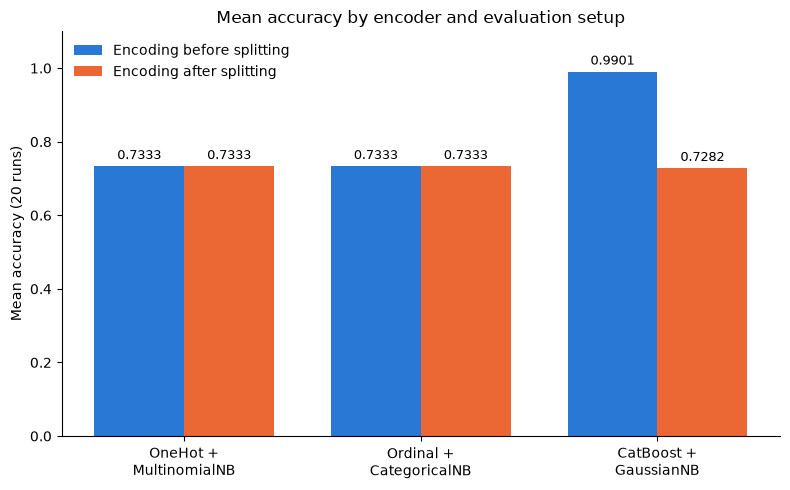

In [6]:
labels = ['OneHot +\nMultinomialNB', 'Ordinal +\nCategoricalNB', 'CatBoost +\nGaussianNB']
before = [np.mean(acc_ohe_mnb), np.mean(acc_ord_cnb), np.mean(acc_cb_gnb)]
after  = [np.mean(acc_ohe_mnb_after), np.mean(acc_ord_cnb_after), np.mean(acc_cb_gnb_after)]

x = np.arange(len(labels))   # position of each group on the x-axis
width = 0.38                 # width of each bar

fig, ax = plt.subplots(figsize=(8, 5))
bars_before = ax.bar(x - width/2, before, width, label='Encoding before splitting', color='#2a78d6')
bars_after  = ax.bar(x + width/2, after,  width, label='Encoding after splitting',  color='#eb6834')

# Write the value on top of each bar
ax.bar_label(bars_before, fmt='%.4f', padding=3, fontsize=9)
ax.bar_label(bars_after,  fmt='%.4f', padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Mean accuracy (20 runs)')
ax.set_ylim(0, 1.1)
ax.set_title('Mean accuracy by encoder and evaluation setup')
ax.legend(loc='upper left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('images/accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Conclusions
**Best encoder:** with the correct workflow (encoding after splitting), *OneHotEncoder* and *OrdinalEncoder* performed best (0.7333), while *CatBoostEncoder* was slightly lower (0.7282). The 0.9901 obtained before splitting is due to data leakage.

**Naive Bayes variant:** *MultinomialNB* with one-hot columns and *CategoricalNB* with ordinal codes are based on the same counts, so they gave identical results. *GaussianNB* is needed for the continuous CatBoost features, but it assumes a normal distribution in each class, which is only an approximation here; this may explain the slightly lower accuracy.

**Before vs after splitting:** no difference for *OneHot* and *Ordinal*, since they do not use the target. A large difference for *CatBoost*, which leaks the test labels when fitted on the full dataset.

**Recommendations:** split the data before fitting any encoder, choose the *Naive Bayes* variant that matches the encoding, handle categories that may appear only in the test set, and check results that look unusually high.